# Analyse exploratoire des données e-commerce Olist

## 1. Importation et chargement des données

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Chargement des données

In [39]:
def charger_donnees():
    tables = {
        "customers": pd.read_csv("data/olist_customers_dataset.csv"),
        "orders": pd.read_csv("data/olist_orders_dataset.csv"),
        "order_items": pd.read_csv("data/olist_order_items_dataset.csv"),
        "payments": pd.read_csv("data/olist_order_payments_dataset.csv"),
        "reviews": pd.read_csv("data/olist_order_reviews_dataset.csv"),
        "products": pd.read_csv("data/olist_products_dataset.csv"),
        "sellers": pd.read_csv("data/olist_sellers_dataset.csv"),
        "geolocation": pd.read_csv("data/olist_geolocation_dataset.csv"),
        "translation": pd.read_csv("data/product_category_name_translation.csv")
    }
    
    return tables
tables = charger_donnees()
print("Les 9 tables sont chargées.")

Les 9 tables sont chargées.


In [40]:
tables["customers"].head()
#tables["orders"].head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


## 2. Exploration initiale des données

In [41]:
# nombre de lignes et de colonnes

for name, df in tables.items():
    print(f"{name} : {df.shape}")

customers : (99441, 5)
orders : (99441, 8)
order_items : (112650, 7)
payments : (103886, 5)
reviews : (99224, 7)
products : (32951, 9)
sellers : (3095, 4)
geolocation : (1000163, 5)
translation : (71, 2)


In [42]:
# apercu des données, les 5 premières lignes de chaque table
#for name, df in tables.items():
   # print(f"\n===== {name.upper()} =====")
    #display(df.head())

## 3. Qualité des données

Informations générales sur les tables

In [43]:

for name, df in tables.items():
    print(f"\n===== {name.upper()} =====")
    df.info()


===== CUSTOMERS =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

===== ORDERS =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchas


### Valeurs manquantes
- Nombre et pourcentage de valeurs manquante

In [44]:
# Parcourir toutes les tables
for name, df in tables.items():

    # Compter les valeurs manquantes par colonne
    missing = df.isnull().sum()

    # Garder uniquement les colonnes qui ont des valeurs manquantes
    missing = missing[missing > 0]

    # Afficher uniquement les tables concernées
    if not missing.empty:

        print(f"\n===== {name.upper()} =====")

        # Calculer le nombre et le pourcentage de valeurs manquantes
        result = pd.DataFrame({
            "Nombre de valeurs manquantes": missing,
            "Pourcentage (%)": (missing / len(df) * 100).round(2)
        })

        # Afficher le résultat
        display(result)


===== ORDERS =====


,Nombre de valeurs manquantes,Pourcentage (%)
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98



===== REVIEWS =====


,Nombre de valeurs manquantes,Pourcentage (%)
review_comment_title,87656,88.34
review_comment_message,58247,58.70



===== PRODUCTS =====


,Nombre de valeurs manquantes,Pourcentage (%)
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01


### Vérification des doublons

In [45]:
# Parcourir toutes les tables
for name, df in tables.items():

    # Compter le nombre de lignes complètement identiques
    duplicates = df.duplicated().sum()

    # Afficher le résultat
    print(f"{name} : {duplicates} doublons")

customers : 0 doublons
orders : 0 doublons
order_items : 0 doublons
payments : 0 doublons
reviews : 0 doublons
products : 0 doublons
sellers : 0 doublons
geolocation : 261831 doublons
translation : 0 doublons


### Conversion de toutes les dates

In [46]:
# Liste des colonnes contenant des dates dans les différentes tables
colonnes_dates = {
    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],
    "order_items": [
        "shipping_limit_date"
    ],
    "reviews": [
        "review_creation_date",
        "review_answer_timestamp"
    ]
}

# Convertir toutes les colonnes de dates au format datetime
for table, colonnes in colonnes_dates.items():
    for colonne in colonnes:
        tables[table][colonne] = pd.to_datetime(
            tables[table][colonne]
        )

print("Toutes les colonnes de dates ont été converties.")

# Vérifier les types des colonnes de dates après conversion
for table, colonnes in colonnes_dates.items():

    print(f"\n===== {table.upper()} =====")

    for colonne in colonnes:
        print(f"{colonne} : {tables[table][colonne].dtype}")

Toutes les colonnes de dates ont été converties.

===== ORDERS =====
order_purchase_timestamp : datetime64[ns]
order_approved_at : datetime64[ns]
order_delivered_carrier_date : datetime64[ns]
order_delivered_customer_date : datetime64[ns]
order_estimated_delivery_date : datetime64[ns]

===== ORDER_ITEMS =====
shipping_limit_date : datetime64[ns]

===== REVIEWS =====
review_creation_date : datetime64[ns]
review_answer_timestamp : datetime64[ns]


###  Vérifier les valeurs manquantes dans les colonnes de dates

In [47]:
# Copier la table orders après la conversion des dates
orders = tables["orders"].copy()
for table, colonnes in colonnes_dates.items():

    print(f"\n===== {table.upper()} =====")

    for colonne in colonnes:

        # Compter les valeurs manquantes
        missing = tables[table][colonne].isna().sum()

        # Afficher le résultat
        print(f"{colonne} : {missing} valeurs manquantes")


===== ORDERS =====
order_purchase_timestamp : 0 valeurs manquantes
order_approved_at : 160 valeurs manquantes
order_delivered_carrier_date : 1783 valeurs manquantes
order_delivered_customer_date : 2965 valeurs manquantes
order_estimated_delivery_date : 0 valeurs manquantes

===== ORDER_ITEMS =====
shipping_limit_date : 0 valeurs manquantes

===== REVIEWS =====
review_creation_date : 0 valeurs manquantes
review_answer_timestamp : 0 valeurs manquantes


In [48]:
orders = tables["orders"].copy()# copier la table orders pour l'analyse
# Vérifier le statut des commandes dont la date de livraison est manquante
orders[
    orders["order_delivered_customer_date"].isna()
]["order_status"].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

On constate que order_delivered_customer_date comportait 2 965 valeurs manquantes, soit 2,98 %. Plutôt que de les supprimer directement, on analyse le statut des commandes concernées. La majorité correspond à des commandes qui ne sont pas indiquées comme livrées, par exemple expédiées, annulées ou en cours de traitement, ce qui peut expliquer l'absence de date de livraison. En revanche, On identifie huit commandes avec le statut delivered mais sans date de livraison client. On les considère donc comme des incohérences potentielles à documenter. 

In [49]:
# Nombre de commandes avec le statut "delivered"
# et une date de livraison renseignée

commandes_livrees_avec_date = orders[
    (orders["order_status"] == "delivered")
    & (orders["order_delivered_customer_date"].notna())
]

print(
    "Commandes livrées avec une date de livraison :",
    commandes_livrees_avec_date["order_id"].nunique()
)

Commandes livrées avec une date de livraison : 96470


## 4. Compréhension du modèle de données

Comprendre comment les 9 tables sont organisées, quelles colonnes permettent de les relier et à quel niveau chaque table décrit les données.

In [50]:
# Vérifier le nombre total de lignes et le nombre de valeurs uniques
# pour les principales clés candidates des 9 tables

cles_candidates = {
    "customers": ["customer_id", "customer_unique_id"],
    "orders": ["order_id"],
    "order_items": ["order_id", "order_item_id"],
    "payments": ["order_id", "payment_sequential"],
    "reviews": ["review_id"],
    "products": ["product_id"],
    "sellers": ["seller_id"],
    "geolocation": ["geolocation_zip_code_prefix"],
    "translation": ["product_category_name"]
}

# Parcourir les 9 tables
for table, colonnes in cles_candidates.items():

    print(f"\n===== {table.upper()} =====")

    # Vérifier chaque clé candidate
    for colonne in colonnes:

        total = len(tables[table])
        uniques = tables[table][colonne].nunique()

        print(
            f"{colonne} → "
            f"{uniques} valeurs uniques sur {total} lignes"
        )


===== CUSTOMERS =====
customer_id → 99441 valeurs uniques sur 99441 lignes
customer_unique_id → 96096 valeurs uniques sur 99441 lignes

===== ORDERS =====
order_id → 99441 valeurs uniques sur 99441 lignes

===== ORDER_ITEMS =====
order_id → 98666 valeurs uniques sur 112650 lignes
order_item_id → 21 valeurs uniques sur 112650 lignes

===== PAYMENTS =====
order_id → 99440 valeurs uniques sur 103886 lignes
payment_sequential → 29 valeurs uniques sur 103886 lignes

===== REVIEWS =====
review_id → 98410 valeurs uniques sur 99224 lignes

===== PRODUCTS =====
product_id → 32951 valeurs uniques sur 32951 lignes

===== SELLERS =====
seller_id → 3095 valeurs uniques sur 3095 lignes

===== GEOLOCATION =====
geolocation_zip_code_prefix → 19015 valeurs uniques sur 1000163 lignes

===== TRANSLATION =====
product_category_name → 71 valeurs uniques sur 71 lignes



Cette analyse montre que customer_id, order_id, product_id, seller_id et product_category_name sont uniques dans leurs tables respectives. À l’inverse, certains identifiants se répètent en raison du niveau de détail des tables. Par exemple, order_id apparaît plusieurs fois dans order_items, car une commande peut contenir plusieurs articles, et dans payments, car une commande peut être associée à plusieurs enregistrements de paiement. review_id n’est pas totalement unique dans reviews, tandis que geolocation_zip_code_prefix apparaît sur de nombreuses lignes dans geolocation. Pour les tables où aucune colonne testée n’est unique seule, il est nécessaire d’étudier d’éventuelles clés composées et la structure de la table. Cette vérification permet donc de mieux comprendre le niveau de détail des données avant d’analyser les relations et d’effectuer les jointures.

### Vérification des clés primaires simples

L'objectif est de vérifier quelles colonnes sont suffisamment uniques pour identifier chaque ligne d’une table et peuvent donc constituer des clés primaires candidates.

In [51]:
# Vérification de l'unicité des clés candidates

cles_candidates = {
    "customers": "customer_id",
    "orders": "order_id",
    "products": "product_id",
    "sellers": "seller_id",
    "translation": "product_category_name"
}

for table, colonne in cles_candidates.items():

    # Nombre total de lignes
    total = len(tables[table])

    # Nombre de valeurs uniques
    uniques = tables[table][colonne].nunique()

    print(f"\n===== {table.upper()} =====")
    print(f"Colonne : {colonne}")
    print(f"Lignes totales : {total}")
    print(f"Valeurs uniques : {uniques}")

    # Vérifier si la colonne est unique
    if total == uniques:
        print("✓ La colonne est unique ")
    else:
        print("⚠ La colonne contient des doublons.")


===== CUSTOMERS =====
Colonne : customer_id
Lignes totales : 99441
Valeurs uniques : 99441
✓ La colonne est unique 

===== ORDERS =====
Colonne : order_id
Lignes totales : 99441
Valeurs uniques : 99441
✓ La colonne est unique 

===== PRODUCTS =====
Colonne : product_id
Lignes totales : 32951
Valeurs uniques : 32951
✓ La colonne est unique 

===== SELLERS =====
Colonne : seller_id
Lignes totales : 3095
Valeurs uniques : 3095
✓ La colonne est unique 

===== TRANSLATION =====
Colonne : product_category_name
Lignes totales : 71
Valeurs uniques : 71
✓ La colonne est unique 


La vérification confirme que customer_id, order_id, product_id, seller_id et product_category_name sont uniques dans leurs tables respectives : le nombre de valeurs uniques est égal au nombre total de lignes. Ces colonnes satisfont donc le critère d’unicité et peuvent servir d’identifiants uniques, et potentiellement de clés primaires pour leurs tables respectives. Cette vérification est importante avant l’étude des relations entre les tables et la réalisation des jointures.

### Vérifier les clés composées de order_items

Objectif :

Vérifier si plusieurs colonnes doivent être combinées pour identifier de manière unique une ligne d'article.

In [52]:
# Vérifier l'unicité de la combinaison order_id + order_item_id de la table order_items

order_items = tables["order_items"]

nb_lignes = len(order_items)

nb_uniques = order_items[
    ["order_id", "order_item_id"]
].drop_duplicates().shape[0]# dupliaction des lignes pour vérifier l'unicité de la combinaison order_id + order_item_id

print(f"Lignes totales : {nb_lignes}")
print(f"Combinaisons uniques : {nb_uniques}")

Lignes totales : 112650
Combinaisons uniques : 112650


Dans la table order_items(article_commande), j’ai constaté que ni order_id ni order_item_id n’était unique individuellement. order_id se répète parce qu’une commande peut contenir plusieurs articles, et order_item_id se répète entre différentes commandes. J’ai donc testé la combinaison (order_id, order_item_id) pour vérifier si elle permettait d’identifier chaque ligne de la table de manière unique. Le résultat confirme que les 112 650 lignes correspondent à 112 650 combinaisons uniques. »

### Vérifier la clé composée de payments (order_id, payment_sequential)

Objectif :

Vérifier si la combinaison de la commande et du numéro séquentiel du paiement permet d'identifier chaque enregistrement de paiement.

In [53]:
# Vérifier l'unicité de la combinaison order_id + payment_sequential de la table payments

payments = tables["payments"]

nb_lignes = len(payments)

nb_uniques = payments[
    ["order_id", "payment_sequential"]
].drop_duplicates().shape[0]

print(f"Lignes totales : {nb_lignes}")
print(f"Combinaisons uniques : {nb_uniques}")

Lignes totales : 103886
Combinaisons uniques : 103886


### Examiner les tables particulières

- Identifier les tables qui ne possèdent pas une clé primaire simple clairement identifiable et comprendre pourquoi leur structure est différente des autres tables.

In [54]:
reviews = tables["reviews"]

# Nombre total de lignes
total = len(reviews)

# Nombre de review_id uniques
review_id_uniques = reviews["review_id"].nunique()

# Nombre de doublons sur review_id
review_id_doublons = reviews["review_id"].duplicated().sum()

print("===== REVIEWS =====")
print(f"Lignes totales : {total}")
print(f"review_id uniques : {review_id_uniques}")
print(f"review_id répétés : {review_id_doublons}")

# Afficher les review_id qui apparaissent plusieurs fois
reviews_repetes = reviews[
    reviews["review_id"].duplicated(keep=False)
].sort_values("review_id")

print("\nExemples de review_id répétés :")
display(reviews_repetes.head(10))

===== REVIEWS =====
Lignes totales : 99224
review_id uniques : 98410
review_id répétés : 814

Exemples de review_id répétés :


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:44


J'ai vérifié son unicité et j'ai constaté qu'il y avait 98 410 valeurs uniques pour 99 224 lignes. Il y a donc des répétitions. Je ne peux pas le considérer comme une clé primaire simple sans investigation supplémentaire. J'ai également constaté qu'un même order_id peut apparaître plusieurs fois dans cette table. 

 ### Vérification globale des principales clés étrangères
 

 Vérifier que les principales clés étrangères présentes dans les tables correspondent bien à des identifiants existants dans les tables de référence.

On va vérifier les 6 relations principales :

- orders.customer_id → customers.customer_id
- order_items.order_id → orders.order_id
- order_items.product_id → products.product_id
- order_items.seller_id → sellers.seller_id
- payments.order_id → orders.order_id
- reviews.order_id → orders.order_id

In [55]:


relations = {
    "orders.customer_id → customers.customer_id":
        ("orders", "customer_id", "customers", "customer_id"),

    "order_items.order_id → orders.order_id":
        ("order_items", "order_id", "orders", "order_id"),

    "order_items.product_id → products.product_id":
        ("order_items", "product_id", "products", "product_id"),

    "order_items.seller_id → sellers.seller_id":
        ("order_items", "seller_id", "sellers", "seller_id"),

    "payments.order_id → orders.order_id":
        ("payments", "order_id", "orders", "order_id"),

    "reviews.order_id → orders.order_id":
        ("reviews", "order_id", "orders", "order_id")
}


# Parcourir toutes les relations
for nom_relation, (table_source, colonne_source,
                   table_reference, colonne_reference) in relations.items():

    # Récupérer les identifiants de la table source
    ids_source = tables[table_source][colonne_source]

    # Vérifier s'ils existent dans la table de référence
    ids_manquants = ids_source[
        ~ids_source.isin(tables[table_reference][colonne_reference])
    ]

    # Nombre d'identifiants différents absents
    nb_manquants = ids_manquants.nunique()

    print(f"\n{nom_relation}")

    if nb_manquants == 0:
        print("✓ Intégrité référentielle respectée")
    else:
        print(
            f"⚠ {nb_manquants} identifiants "
            "absents de la table de référence"
        )


orders.customer_id → customers.customer_id
✓ Intégrité référentielle respectée

order_items.order_id → orders.order_id
✓ Intégrité référentielle respectée

order_items.product_id → products.product_id
✓ Intégrité référentielle respectée

order_items.seller_id → sellers.seller_id
✓ Intégrité référentielle respectée

payments.order_id → orders.order_id
✓ Intégrité référentielle respectée

reviews.order_id → orders.order_id
✓ Intégrité référentielle respectée


La vérification de l'intégrité référentielle montre que les principales clés étrangères correspondent bien à des identifiants existants dans les tables de référence. Aucun identifiant orphelin n'a été détecté. Les principales relations entre les tables sont donc cohérentes sur ce point.

### Vérification globale des relations 1 → N

Vérifier automatiquement les relations entre les tables et identifier combien d'enregistrements de la table « enfant » sont associés à un même enregistrement de la table « parent

In [56]:


relations_1N = {
    "customers → orders": ("customers", "customer_id", "orders", "customer_id"),
    "orders → order_items": ("orders", "order_id", "order_items", "order_id"),
    "products → order_items": ("products", "product_id", "order_items", "product_id"),
    "sellers → order_items": ("sellers", "seller_id", "order_items", "seller_id"),
    "orders → payments": ("orders", "order_id", "payments", "order_id"),
    "orders → reviews": ("orders", "order_id", "reviews", "order_id")
}


for relation, (table_parent, id_parent,
               table_enfant, id_enfant) in relations_1N.items():

    # Compter le nombre d'enregistrements associés
    nombre_associes = (
        tables[table_enfant]
        .groupby(id_enfant)
        .size()
    )

    # Nombre de valeurs de la table parent ayant au moins
    # un enregistrement dans la table enfant
    parents_associes = nombre_associes.shape[0]

    # Nombre maximum d'enregistrements associés à un même parent
    maximum = nombre_associes.max()

    # Nombre de parents associés à plusieurs enfants
    plusieurs = (nombre_associes > 1).sum()

    print(f"\n===== {relation.upper()} =====")
    print(f"{table_parent} : {tables[table_parent][id_parent].nunique()} identifiants")
    print(f"{table_enfant} : {len(tables[table_enfant])} lignes")
    print(f"Parents ayant au moins un élément associé : {parents_associes}")
    print(f"Nombre maximum d'éléments associés à un parent : {maximum}")
    print(f"Parents avec plusieurs éléments associés : {plusieurs}")


===== CUSTOMERS → ORDERS =====
customers : 99441 identifiants
orders : 99441 lignes
Parents ayant au moins un élément associé : 99441
Nombre maximum d'éléments associés à un parent : 1
Parents avec plusieurs éléments associés : 0

===== ORDERS → ORDER_ITEMS =====
orders : 99441 identifiants
order_items : 112650 lignes
Parents ayant au moins un élément associé : 98666
Nombre maximum d'éléments associés à un parent : 21
Parents avec plusieurs éléments associés : 9803

===== PRODUCTS → ORDER_ITEMS =====
products : 32951 identifiants
order_items : 112650 lignes
Parents ayant au moins un élément associé : 32951
Nombre maximum d'éléments associés à un parent : 527
Parents avec plusieurs éléments associés : 14834

===== SELLERS → ORDER_ITEMS =====
sellers : 3095 identifiants
order_items : 112650 lignes
Parents ayant au moins un élément associé : 3095
Nombre maximum d'éléments associés à un parent : 2033
Parents avec plusieurs éléments associés : 2586

===== ORDERS → PAYMENTS =====
orders : 9

L'analyse des relations montre que plusieurs tables présentent une relation de type 1 → N. Un enregistrement de la table parent peut être associé à plusieurs enregistrements dans la table enfant. Par exemple, une commande peut contenir plusieurs articles et peut également être associée à plusieurs enregistrements de paiement. Cette vérification permet de confirmer la structure relationnelle du modèle et d'anticiper les effets des jointures sur le nombre de lignes.

 ### Vérification du niveau de détail des principales tables


In [57]:


niveau_detail = {
    "customers": "1 ligne = 1 enregistrement client",
    "orders": "1 ligne = 1 commande",
    "order_items": "1 ligne = 1 article dans une commande",
    "payments": "1 ligne = 1 enregistrement de paiement",
    "reviews": "1 ligne = 1 enregistrement d'avis",
    "products": "1 ligne = 1 produit",
    "sellers": "1 ligne = 1 vendeur",
    "geolocation": "1 ligne = 1 observation géographique",
    "translation": "1 ligne = 1 catégorie et sa traduction"
}

for table, description in niveau_detail.items():
    print(f"{table:<15} → {description}")

customers       → 1 ligne = 1 enregistrement client
orders          → 1 ligne = 1 commande
order_items     → 1 ligne = 1 article dans une commande
payments        → 1 ligne = 1 enregistrement de paiement
reviews         → 1 ligne = 1 enregistrement d'avis
products        → 1 ligne = 1 produit
sellers         → 1 ligne = 1 vendeur
geolocation     → 1 ligne = 1 observation géographique
translation     → 1 ligne = 1 catégorie et sa traduction


## 5. Préparation et jointure des données

Objectif:

- Construire une table d'analyse à partir des différentes tables Olist, en utilisant les bonnes clés de jointure tout en conservant la population nécessaire à l'analyse et en évitant de multiplier artificiellement les lignes.

- Regrouper les commandes avec les informations
- clients, articles, produits, catégories et vendeurs.
- Les LEFT JOIN permettent de conserver toutes les commandes.

In [58]:

# Table de départ : 1 ligne = 1 commande
df_analyse = tables["orders"].copy()
print("Table de départ (orders) :", df_analyse.shape)


# Ajout des informations clients
df_analyse = df_analyse.merge(# ajout des informations clients à la table de départ
    tables["customers"],
    on="customer_id",
    how="left",
    validate="m:1"
)
print("Après ajout de customers :", df_analyse.shape)


# Ajout des articles : une commande peut contenir plusieurs articles (1:N)
# À partir d'ici : 1 ligne ≈ 1 article d'une commande
df_analyse = df_analyse.merge(
    tables["order_items"],
    on="order_id",
    how="left",
    validate="1:m"
)
print("Après ajout de order_items :", df_analyse.shape)


# Ajout des caractéristiques des produits
df_analyse = df_analyse.merge(
    tables["products"],
    on="product_id",
    how="left",
    validate="m:1"
)
print("Après ajout de products :", df_analyse.shape)


# Ajout de la traduction des catégories
df_analyse = df_analyse.merge(
    tables["translation"],
    on="product_category_name",
    how="left",
    validate="m:1"
)
print("Après ajout de translation :", df_analyse.shape)


# Ajout des informations vendeurs
df_analyse = df_analyse.merge(
    tables["sellers"],
    on="seller_id",
    how="left",
    validate="m:1",
    suffixes=("_customer", "_seller")
)
print("Après ajout de sellers :", df_analyse.shape)


# Vérification du résultat
display(df_analyse.head())

Table de départ (orders) : (99441, 8)
Après ajout de customers : (99441, 12)
Après ajout de order_items : (113425, 18)
Après ajout de products : (113425, 26)
Après ajout de translation : (113425, 27)
Après ajout de sellers : (113425, 30)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,268.0,4.0,500.0,19.0,8.0,13.0,housewares,9350.0,maua,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,178.0,1.0,400.0,19.0,13.0,19.0,perfumery,31570.0,belo horizonte,SP
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,232.0,1.0,420.0,24.0,19.0,21.0,auto,14840.0,guariba,SP
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,...,468.0,3.0,450.0,30.0,10.0,20.0,pet_shop,31842.0,belo horizonte,MG
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,...,316.0,4.0,250.0,51.0,15.0,15.0,stationery,8752.0,mogi das cruzes,SP


Les jointures conservent 99 441 lignes jusqu'à l'ajout de order_items. Le nombre de lignes passe ensuite à 113 425, ce qui est cohérent avec la relation 1:N entre commandes et articles. Les jointures suivantes n'augmentent pas le nombre de lignes, ce qui indique qu'elles n'introduisent pas de fan-out supplémentaire.


### Nombre et évolution des commandes

- Comment l'activité d'Olist évolue-t-elle dans le temps ?

- Pour compter les commandes, on utilise orders directement plutôt que df_analyse, car dans df_analyse une commande peut apparaître plusieurs fois à cause des articles.

In [59]:
# Copier la table orders pour l'analyse
orders = tables["orders"].copy()

# Nombre total de commandes
nb_commandes = orders["order_id"].nunique()

print(f"Nombre total de commandes : {nb_commandes:,}")

# Regrouper les commandes par mois
commandes_mois = (
    orders
    .set_index("order_purchase_timestamp")  # Utiliser la date de commande comme index
    .resample("ME")["order_id"]             # Regrouper les commandes par mois
    .nunique()                               # Compter les commandes uniques
)

display(commandes_mois.head())

Nombre total de commandes : 99,441


order_purchase_timestamp
2016-09-30      4
2016-10-31    324
2016-11-30      0
2016-12-31      1
2017-01-31    800
Freq: ME, Name: order_id, dtype: int64

Ce resultat Vérifie le nombre total de commandes, qui est de 99 441. Ensuite, j’ai regroupé les commandes par mois à partir de leur date d’achat afin d’étudier l’évolution de l’activité dans le temps. Chaque valeur représente donc le nombre de commandes uniques enregistrées au cours du mois. »

## 6. Analyse exploratoire et visualisations

### 6.1 Évolution mensuelle du nombre de commandes

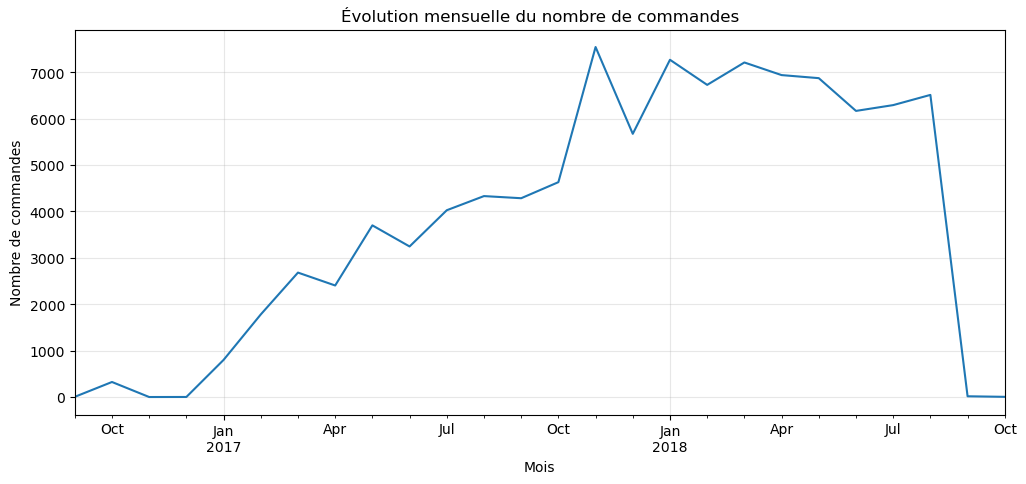

In [60]:
# Visualiser l'évolution mensuelle des commandes
plt.figure(figsize=(12, 5))

commandes_mois.plot()

plt.title("Évolution mensuelle du nombre de commandes")
plt.xlabel("Mois")
plt.ylabel("Nombre de commandes")
plt.grid(alpha=0.3)

plt.show()

Ce graphique représente l’évolution mensuelle du nombre de commandes. J’ai choisi une courbe car il s’agit d’une série temporelle. On observe une forte progression de l’activité à partir de janvier 2017, avec un pic autour de novembre 2017 à plus de 7 000 commandes. En 2018, le volume reste globalement élevé malgré quelques fluctuations. Enfin, la forte baisse observée en fin de période doit être interprétée avec prudence, car les dernières données sont incomplètes, notamment octobre 2018 qui s’arrête au 17 du mois

In [61]:
# Vérifier le nombre exact de commandes sur les derniers mois
commandes_mois.tail(6)

order_purchase_timestamp
2018-05-31    6873
2018-06-30    6167
2018-07-31    6292
2018-08-31    6512
2018-09-30      16
2018-10-31       4
Freq: ME, Name: order_id, dtype: int64

Comme j’ai observé une chute très importante à la fin de la courbe, j’ai vérifié les valeurs des derniers mois. On passe de 6 512 commandes en août à seulement 16 en septembre et 4 en octobre. Cette rupture très brutale m’amène à être prudente : elle peut être liée à une couverture incomplète des données en fin de période plutôt qu’à une réelle baisse de l’activité.


### 6.2 Distribution des prix


In [62]:
# Sélection des prix et suppression des éventuelles valeurs manquantes
prix = tables["order_items"]["price"].dropna()

# Statistiques descriptives des prix
prix.describe()


count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

 112 650 prix exploitables.

Les principales valeurs sont :

Moyenne : 120,65
Médiane : 74,99
Minimum : 0,85
Maximum : 6 735
Q1 : 39,90 → 25 % des prix sont inférieurs ou égaux à 39,90.
Q3 : 134,90 → 75 % des prix sont inférieurs ou égaux à 134,90.
Écart-type : 183,63 → les prix sont assez dispersés autour de la moyenne.

Le point particulièrement intéressant est que la moyenne (120,65) est nettement supérieure à la médiane (74,99). Cela suggère une distribution asymétrique vers les valeurs élevées : quelques prix très élevés tirent la moyenne vers le haut.

Le maximum de 6 735, très éloigné du troisième quartile de 134,90, suggère également la présence de valeurs extrêmes, que tu vas justement étudier ensuite avec l'IQR et le boxplot.

# Analyse de la distribution des prix des articles


Visualiser la répartition des prix afin d’identifier leur concentration, la forme de la distribution et la présence éventuelle de valeurs extrêmes.


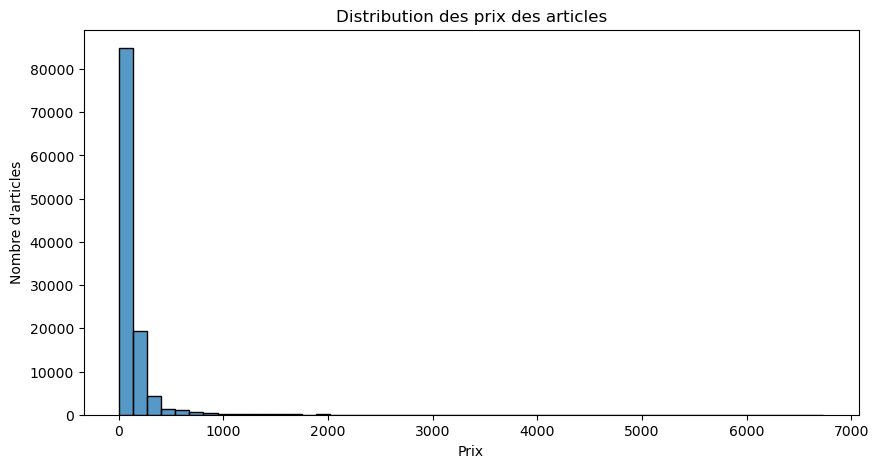

In [63]:
# Visualisation de la distribution des prix
plt.figure(figsize=(10, 5))

sns.histplot(prix, bins=50)

plt.title("Distribution des prix des articles")
plt.xlabel("Prix")
plt.ylabel("Nombre d'articles")

plt.show()

L’histogramme montre une forte concentration des articles dans les faibles niveaux de prix. La fréquence diminue progressivement lorsque le prix augmente, tandis que quelques articles présentent des prix très élevés. La distribution est donc asymétrique vers la droite. Cette observation est cohérente avec les statistiques descriptives : la moyenne (120,65) est supérieure à la médiane (74,99), ce qui indique que les prix élevés influencent la moyenne. La présence de valeurs extrêmes sera ensuite étudiée à l’aide de la méthode de l’IQR et du boxplot.

### 6.3 Analyse des valeurs extrêmes — IQR 


In [64]:


# Calcul des quartiles et de l'écart interquartile (IQR)
Q1 = prix.quantile(0.25)
Q3 = prix.quantile(0.75)
IQR = Q3 - Q1

# Définition des bornes pour identifier les valeurs aberrantes
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

print("\nQ1 :", round(Q1, 2))# affichage des résultats avec arrondi à 2 décimales
print("Q3 :", round(Q3, 2))
print("IQR :", round(IQR, 2))
print("Borne inférieure :", round(borne_inf, 2))
print("Borne supérieure :", round(borne_sup, 2))

# Identification des valeurs situées en dehors des bornes de l'IQR
nb_outliers = ((prix < borne_inf) | (prix > borne_sup)).sum()

# Calcul de la proportion de valeurs aberrantes
print("Nombre de valeurs aberrantes :", nb_outliers)
print(
    "Pourcentage de valeurs aberrantes :",
    round(nb_outliers / len(prix) * 100, 2),
    "%"
)


Q1 : 39.9
Q3 : 134.9
IQR : 95.0
Borne inférieure : -102.6
Borne supérieure : 277.4
Nombre de valeurs aberrantes : 8427
Pourcentage de valeurs aberrantes : 7.48 %


Le premier quartile (Q1) est de 39,90 et le troisième quartile (Q3) de 134,90, soit un écart interquartile (IQR) de 95. Selon la règle de l’IQR, les valeurs situées en dehors de l’intervalle [-102,60 ; 277,40] sont considérées comme potentiellement aberrantes. Comme les prix observés sont positifs et que le minimum est de 0,85, aucune valeur ne se situe sous la borne inférieure. En revanche, les prix supérieurs à 277,40 sont considérés comme des valeurs extrêmes. Ils représentent 8 427 observations, soit 7,48 % des prix. Ces valeurs ne sont pas supprimées automatiquement, car elles peuvent correspondre à des produits réellement plus coûteux.

Pour bien comprendre le calcul


 IQR = Q3-Q1 = 134,90-39,90 = 95 

Puis :

Borne inférieure = Q1-1,5* IQR = -102,60 
Borne sup =Q3+1,5*IQR=277,40

### 6.4  Analyse des valeurs aberrantes des prix-  Boxplot

Objectif :

Visualiser la dispersion des prix, la médiane, les quartiles et identifier les valeurs potentiellement aberrantes à l’aide de la méthode de l’IQR.

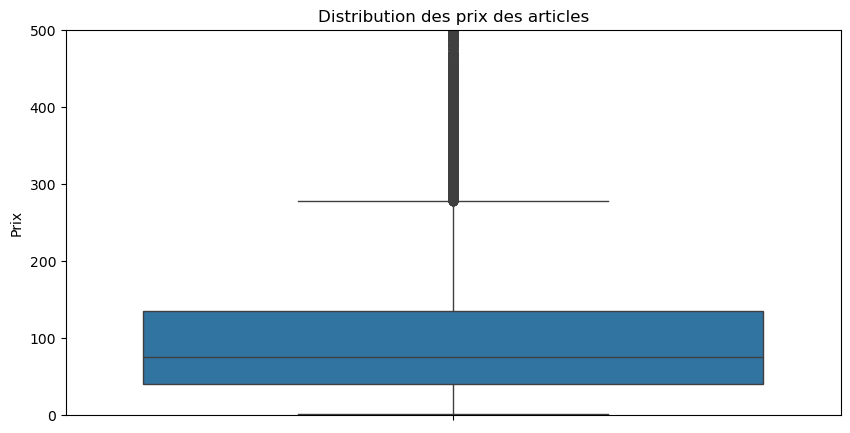

In [65]:
# Boxplot sur la zone principale des prix
plt.figure(figsize=(10, 5))

sns.boxplot(y=prix)

plt.ylim(0,500)

plt.title("Distribution des prix des articles")
plt.ylabel("Prix")

plt.show()

Le boxplot montre que 50 % des prix se situent entre 39,90 (Q1) et 134,90 (Q3), avec une médiane de 74,99. Les nombreuses valeurs situées au-delà de la moustache supérieure confirment la présence de prix extrêmes et une distribution asymétrique vers les valeurs élevées. Ces valeurs ne sont pas supprimées automatiquement, car elles peuvent correspondre à des produits réellement plus chers. L’affichage est limité à 500 pour faciliter la lecture du graphique ; les valeurs supérieures sont toujours présentes dans les données.


 ### 6.5 Comparer la distribution des prix entre les cinq catégories de produits les plus représentées

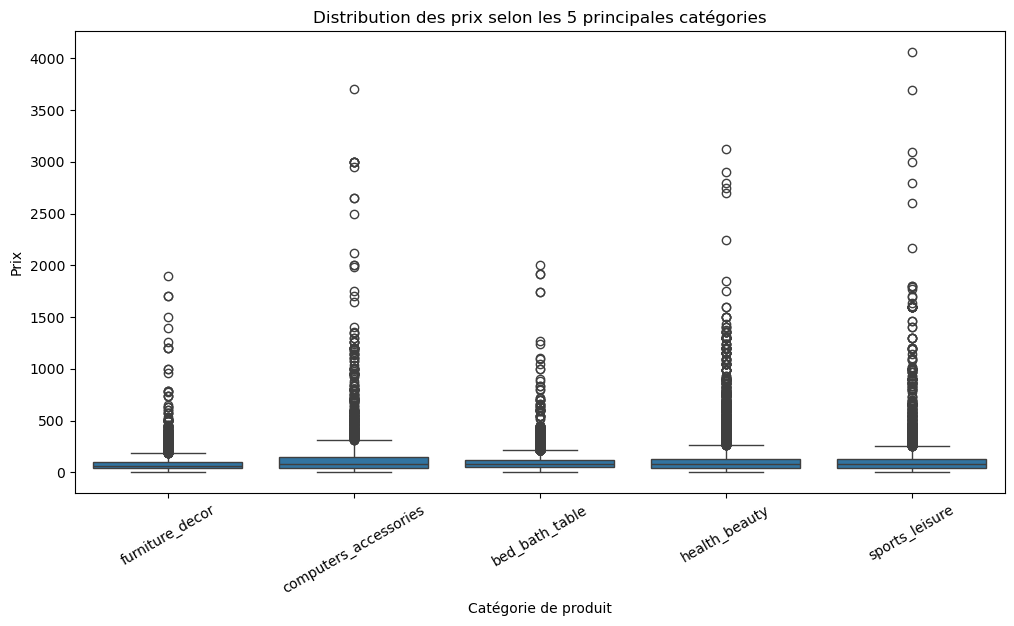

In [66]:
# Sélectionner les 5 catégories ayant le plus d'articles
top5_categories = (
    df_analyse["product_category_name_english"]
    .value_counts()
    .head(5)
    .index
)

# Filtrer les données sur ces 5 catégories
df_top5 = df_analyse[
    df_analyse["product_category_name_english"].isin(top5_categories)
]

# Créer le boxplot comparatif
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_top5,
    x="product_category_name_english",
    y="price"
)

plt.title("Distribution des prix selon les 5 principales catégories")
plt.xlabel("Catégorie de produit")
plt.ylabel("Prix")

plt.xticks(rotation=30)
plt.show()

Ce boxplot compare la distribution des prix entre les cinq catégories de produits les plus représentées. Les distributions varient selon les catégories, notamment en termes de médiane et de dispersion. Toutes les catégories présentent également de nombreuses valeurs extrêmes vers les prix élevés. Cela montre que les prix sont dispersés au sein de chaque catégorie et que certains produits sont nettement plus chers que la majorité des produits de leur catégorie.

### 6.6 Catégories de produits les plus vendues - Barplot 

Objectif :

Identifier et comparer les 10 catégories ayant le plus grand nombre d’articles vendus afin de repérer les catégories les plus représentées dans les ventes.

product_category_name_english
bed_bath_table           11115
health_beauty             9670
sports_leisure            8641
furniture_decor           8334
computers_accessories     7827
housewares                6964
watches_gifts             5991
telephony                 4545
garden_tools              4347
auto                      4235
Name: count, dtype: int64

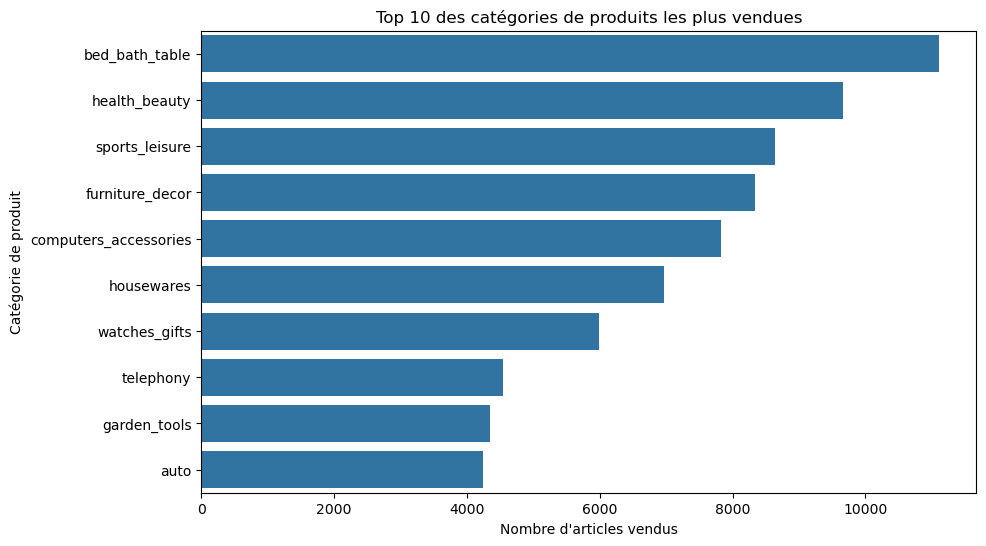

In [67]:

# Comptage du nombre d'articles vendus par catégorie
top_categories = (
    df_analyse["product_category_name_english"]
    .value_counts()
    .head(10)
)

display(top_categories)

# Visualisation des 10 catégories avec le plus d'articles vendus
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_categories.values,
    y=top_categories.index
)

plt.title("Top 10 des catégories de produits les plus vendues")
plt.xlabel("Nombre d'articles vendus")
plt.ylabel("Catégorie de produit")

plt.show()

Ce graphique présente les 10 catégories ayant le plus grand nombre d’articles vendus. La catégorie bed_bath_table arrive en première position avec plus de 11 000 articles, suivie de health_beauty, puis sports_leisure. On constate donc que certaines catégories sont beaucoup plus représentées dans les ventes que d’autres. Cette analyse permet d’identifier les catégories qui concentrent le plus grand volume d’articles vendus.

### 6.7 Analyse des délais de livraison

Objectif :

Analyser les délais de livraison afin d’évaluer la performance logistique et d’identifier les commandes livrées en retard.

In [68]:


# Sélection des commandes disposant d'une date de livraison
livraisons = tables["orders"].dropna( # supprimer les lignes avec des valeurs manquantes dans la colonne order_delivered_customer_date
    subset=["order_delivered_customer_date"]
).copy()

# Calcul du délai réel de livraison en jours
livraisons["delai_livraison"] = (
    livraisons["order_delivered_customer_date"]
    - livraisons["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Calcul de l'écart entre la livraison réelle et la date estimée
livraisons["ecart_estimation"] = (
    livraisons["order_delivered_customer_date"]
    - livraisons["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Statistiques descriptives
display(
    livraisons[
        ["delai_livraison", "ecart_estimation"]
    ].describe()
)

,delai_livraison,ecart_estimation
count,96476.000000,96476.000000
mean,12.558702,-11.179120
std,9.546530,10.186113
min,0.533414,-146.016123
25%,6.766403,-16.244384
50%,10.217755,-11.948941
75%,15.720327,-6.390000
max,209.628611,188.975081


Sur les 96 476 commandes analysées, le délai moyen de livraison est de 12,56 jours, avec une médiane de 10,22 jours. L’écart moyen avec la date estimée est de −11,18 jours, ce qui indique que les commandes sont globalement livrées avant la date prévue

In [69]:
# Classification des commandes selon le respect de la date estimée
livraisons["statut_livraison"] = np.where(
    livraisons["ecart_estimation"] > 0,
    "En retard",
    "À temps ou en avance"
)

# Nombre de commandes par statut
statut_livraison = livraisons["statut_livraison"].value_counts()

display(statut_livraison)

statut_livraison
À temps ou en avance    88649
En retard                7827
Name: count, dtype: int64

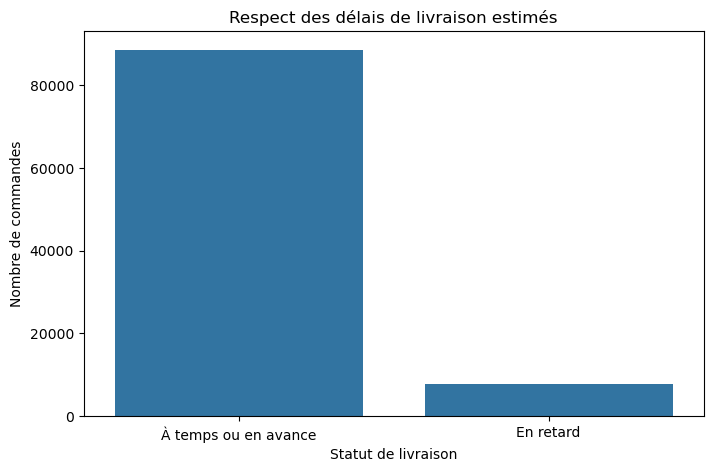

In [70]:
# Visualisation du respect des délais de livraison
plt.figure(figsize=(8, 5))

sns.barplot(
    x=statut_livraison.index,
    y=statut_livraison.values
)

plt.title("Respect des délais de livraison estimés")
plt.xlabel("Statut de livraison")
plt.ylabel("Nombre de commandes")

plt.show()

La grande majorité des commandes analysées est livrée à temps ou en avance (88 649, soit environ 91,9 %), contre 7 827 commandes en retard (8,1 %). Cela indique un respect globalement élevé des délais de livraison estimés.

### 6.8 Retard de livraison et satisfaction client

Objectif :

Analyser la répartition des notes attribuées par les clients afin d’évaluer leur niveau global de satisfaction.

In [71]:

reviews = tables["reviews"].copy()

# Statistiques descriptives des notes
display(reviews["review_score"].describe())

# Nombre d'avis pour chaque note
notes = reviews["review_score"].value_counts().sort_index()

display(notes)

count    99224.000000
mean         4.086421
std          1.347579
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: review_score, dtype: float64

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

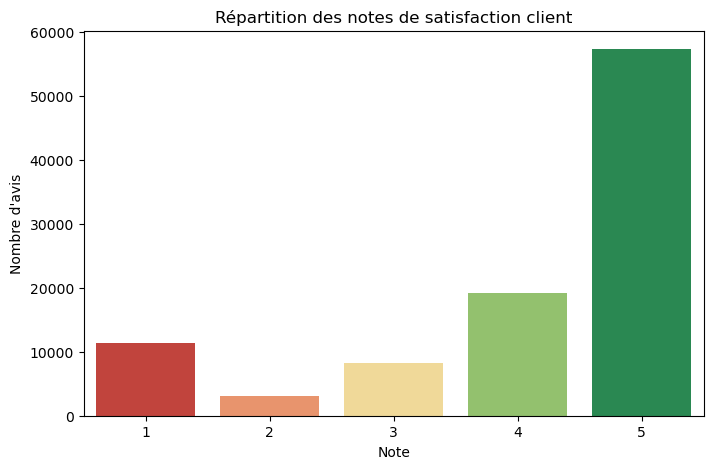

In [72]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=notes.index,
    y=notes.values,
    palette=["#d73027", "#fc8d59", "#fee08b", "#91cf60", "#1a9850"],
    hue=notes.index,
    legend=False
)

plt.title("Répartition des notes de satisfaction client")
plt.xlabel("Note")
plt.ylabel("Nombre d'avis")

plt.show()

Les avis sont majoritairement positifs, avec une forte concentration sur les notes 4 et 5, et particulièrement sur la note 5. La note moyenne de 4,09/5 confirme un niveau global de satisfaction élevé, malgré la présence d’avis négatifs.

### 6.9 Retard de livraison et satisfaction client

Objectif :

Comparer la note moyenne des clients selon que leur commande a été livrée en retard ou à temps afin d’étudier le lien entre la performance logistique et la satisfaction client

In [73]:


# Calcul de la note moyenne par commande
reviews_commande = (
    tables["reviews"]
    .groupby("order_id", as_index=False)["review_score"]
    .mean()
)

# Ajout de la satisfaction aux données de livraison
livraisons_reviews = livraisons.merge(
    reviews_commande,
    on="order_id",
    how="left",
    validate="1:1"
)

# Note moyenne selon le respect du délai estimé
satisfaction_delai = (
    livraisons_reviews
    .groupby("statut_livraison")["review_score"]
    .mean()
)

display(satisfaction_delai)

statut_livraison
En retard               2.566562
À temps ou en avance    4.294151
Name: review_score, dtype: float64

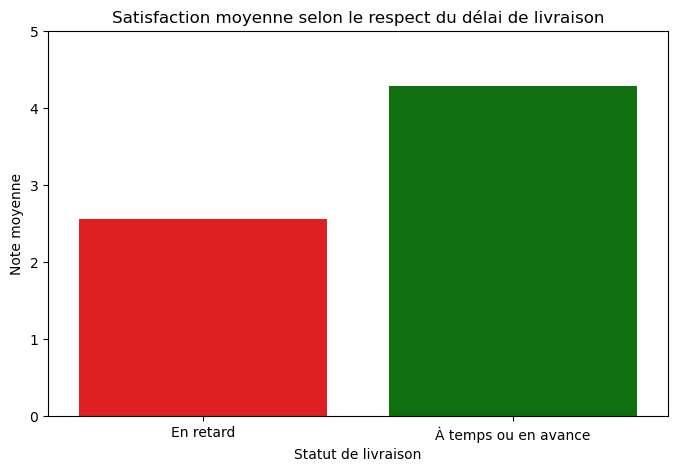

In [74]:
# Visualisation de la satisfaction selon le respect du délai
plt.figure(figsize=(8, 5))

sns.barplot(
    x=satisfaction_delai.index,
    y=satisfaction_delai.values,
    hue=satisfaction_delai.index,
    palette={
        "En retard": "red",
        "À temps ou en avance": "green"
    },
    legend=False
)

plt.title("Satisfaction moyenne selon le respect du délai de livraison")
plt.xlabel("Statut de livraison")
plt.ylabel("Note moyenne")
plt.ylim(0, 5)

plt.show()

Les commandes livrées à temps ou en avance obtiennent une note moyenne de 4,29/5, contre 2,57/5 pour les commandes en retard. Le respect des délais est donc associé à un niveau de satisfaction client plus élevé.

### 6.10 Relation entre poids et frais de livraison

Objectif :

Étudier la relation entre le poids des produits et les frais de livraison afin de déterminer si les produits plus lourds sont associés à des frais de transport plus élevés.

In [75]:

# Sélection des deux variables étudiées
# Suppression des lignes contenant une valeur manquante
poids_fret = df_analyse[
    ["product_weight_g", "freight_value"]
].dropna()

# Statistiques descriptives
display(poids_fret.describe())

,product_weight_g,freight_value
count,112632.000000,112632.000000
mean,2093.672047,19.991071
std,3751.596884,15.807467
min,0.000000,0.000000
25%,300.000000,13.080000
50%,700.000000,16.260000
75%,1800.000000,21.150000
max,40425.000000,409.680000


# Visualisation de la relation entre le poids

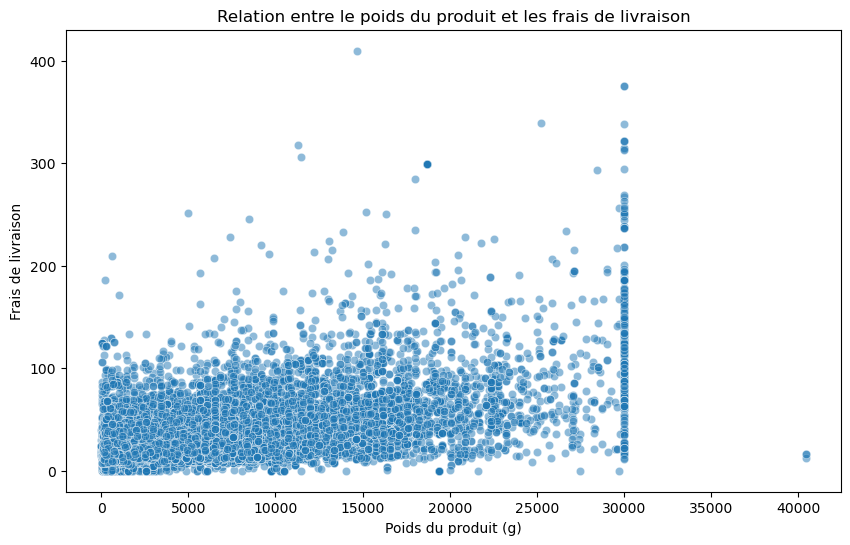

In [76]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=poids_fret,
    x="product_weight_g",
    y="freight_value",
    alpha=0.5
)

plt.title("Relation entre le poids du produit et les frais de livraison")
plt.xlabel("Poids du produit (g)")
plt.ylabel("Frais de livraison")

plt.show()

Le nuage de points suggère une relation positive entre le poids des produits et les frais de livraison : les produits plus lourds ont généralement des frais de livraison plus élevés. Cependant, la dispersion importante des observations indique que le poids n’est pas le seul facteur associé aux frais de livraison.

### 6.11 Corrélation entre poids et frais de livraison

Objectif

Mesurer la force et le sens de la relation entre le poids des produits et les frais de livraison à l’aide des coefficients de corrélation de Pearson et de Spearman.

In [77]:
# Calcul des corrélations entre le poids
# et les frais de livraison

correlation_pearson = poids_fret[
    "product_weight_g"
].corr(
    poids_fret["freight_value"],# calcul de la corrélation de Pearson entre le poids du produit et les frais de livraison
    method="pearson"
)

correlation_spearman = poids_fret[
    "product_weight_g"
].corr(
    poids_fret["freight_value"],# calcul de la corrélation de Spearman entre le poids du produit et les frais de livraison
    method="spearman"
)

print(f"Corrélation de Pearson : {correlation_pearson:.3f}")
print(f"Corrélation de Spearman : {correlation_spearman:.3f}")

Corrélation de Pearson : 0.610
Corrélation de Spearman : 0.447


La corrélation de Pearson est de 0,610 et celle de Spearman de 0,447. Les deux coefficients sont positifs, ce qui indique que les frais de livraison ont globalement tendance à augmenter lorsque le poids du produit augmente. La relation est toutefois imparfaite, ce qui suggère que d’autres facteurs peuvent également être associés aux frais de livraison

### 6.12 Visualisation de la tendance entre le poids et les frais de livraison

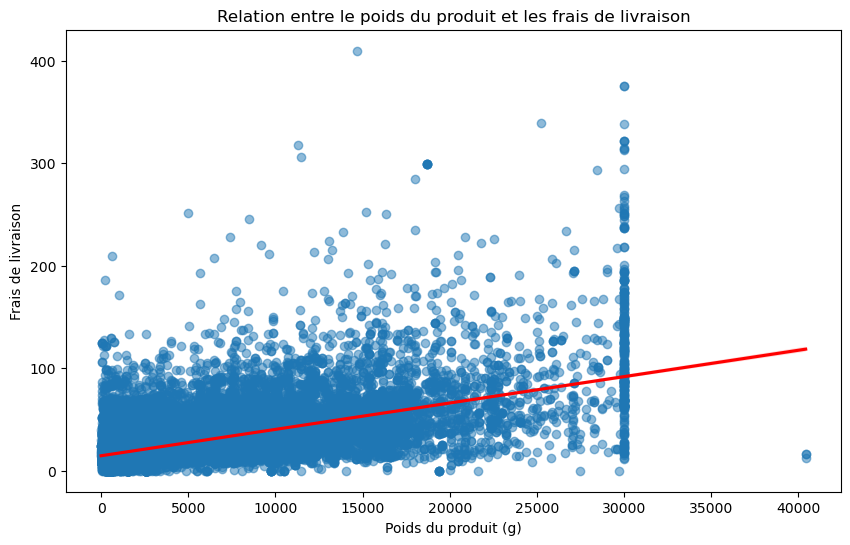

In [79]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=poids_fret,
    x="product_weight_g",
    y="freight_value",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Relation entre le poids du produit et les frais de livraison")
plt.xlabel("Poids du produit (g)")
plt.ylabel("Frais de livraison")
plt.show()

La droite de tendance croissante confirme une relation positive entre le poids des produits et les frais de livraison : les produits plus lourds tendent à être associés à des frais de livraison plus élevés.

Cependant, la dispersion importante des observations autour de la droite montre que le poids n'explique pas à lui seul les variations des frais de livraison. D'autres facteurs peuvent également intervenir.